In [ ]:
# импорт необходимых библиотек работы с данными
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# DIR PATH to DATA
dir_path = "/content/drive/My Drive/Colab Notebooks/"

Mounted at /content/drive


In [ ]:
csv_file_path_1 = dir_path + 'bank.csv'
csv_file_path_1

'/content/drive/My Drive/Colab Notebooks/bank.csv'

In [ ]:
# Чтение данных из файла bank.csv (разделитель - запятая)
df = pd.read_csv(csv_file_path_1, sep = ',')
print(df.shape)

(11162, 17)


In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [ ]:
print('Явных пропусков (NaN):', df.isnull().sum().sum())
for col in df.select_dtypes(exclude='number').columns:
    n = (df[col] == 'unknown').sum()
    if n > 0:
        print(f'{col}: {n} значений unknown')

Явных пропусков (NaN): 0
job: 70 значений unknown
education: 497 значений unknown
contact: 2346 значений unknown
poutcome: 8326 значений unknown


In [ ]:
df = df.replace('unknown', np.nan)

In [ ]:
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Пропуски': missing, 'Процент': missing_percent})
missing_df = missing_df[missing_df['Пропуски'] > 0].sort_values('Процент', ascending=False)
print(missing_df)

           Пропуски    Процент
poutcome       8326  74.592367
contact        2346  21.017739
education       497   4.452607
job              70   0.627128


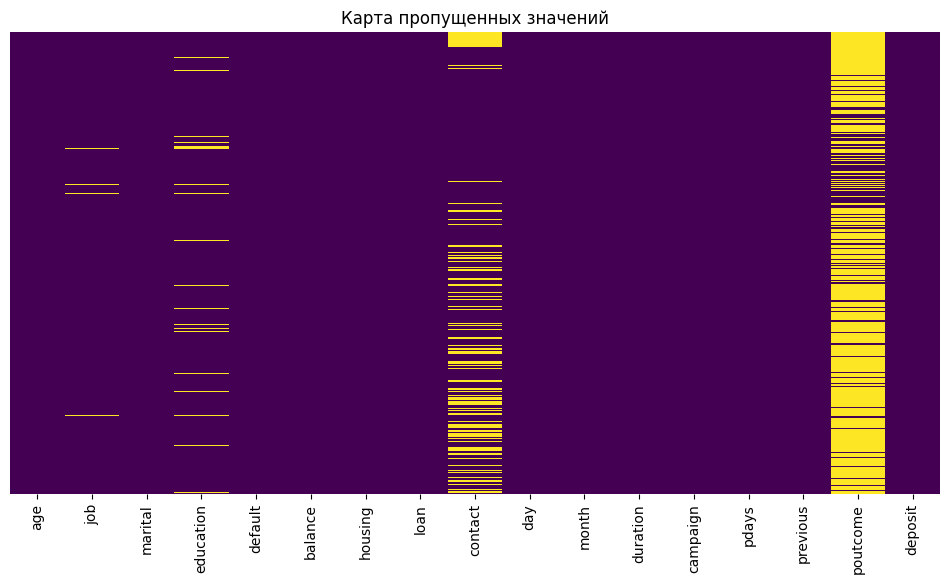

In [ ]:
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Карта пропущенных значений')
plt.show()

In [ ]:
print('pdays == -1:', (df['pdays'] == -1).sum(), '| poutcome NaN:', df['poutcome'].isnull().sum())

pdays == -1: 8324 | poutcome NaN: 8326


In [ ]:
# poutcome - отдельная категория
df['poutcome'] = df['poutcome'].fillna('none')

# job, education, contact - мода
for col in ['job', 'education', 'contact']:
    df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Пропуски': missing, 'Процент': missing_percent})
missing_df = missing_df[missing_df['Пропуски'] > 0].sort_values('Процент', ascending=False)
print(missing_df)
print('Пропусков осталось:', df.isnull().sum().sum())

Empty DataFrame
Columns: [Пропуски, Процент]
Index: []
Пропусков осталось: 0


In [ ]:
num_cols = ['age', 'balance', 'duration', 'campaign', 'previous']
df[num_cols].describe()

,age,balance,duration,campaign,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,371.993818,2.508421,0.832557
std,11.913369,3225.413326,347.128386,2.722077,2.292007
min,18.000000,-6847.000000,2.000000,1.000000,0.000000
25%,32.000000,122.000000,138.000000,1.000000,0.000000
50%,39.000000,550.000000,255.000000,2.000000,0.000000
75%,49.000000,1708.000000,496.000000,3.000000,1.000000
max,95.000000,81204.000000,3881.000000,63.000000,58.000000


<Axes: ylabel='Frequency'>

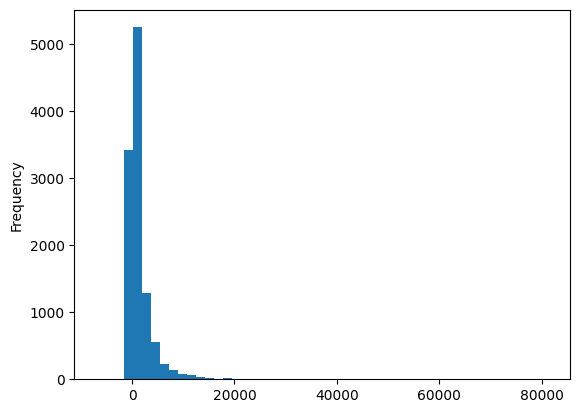

In [ ]:
#Построить гистограмму
df['balance'].plot(kind='hist', bins = 50)

In [ ]:
df.loc[df['balance'] >= df['balance'].max() - 5000]

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
3043,84,retired,married,secondary,no,81204,no,no,telephone,28,dec,679,1,313,2,other,yes
3380,84,retired,married,secondary,no,81204,no,no,telephone,1,apr,390,1,94,3,success,yes


In [ ]:
df.loc[df['balance'] == df['balance'].min()]

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
6797,49,management,married,tertiary,yes,-6847,no,yes,cellular,21,jul,206,1,-1,0,none,no


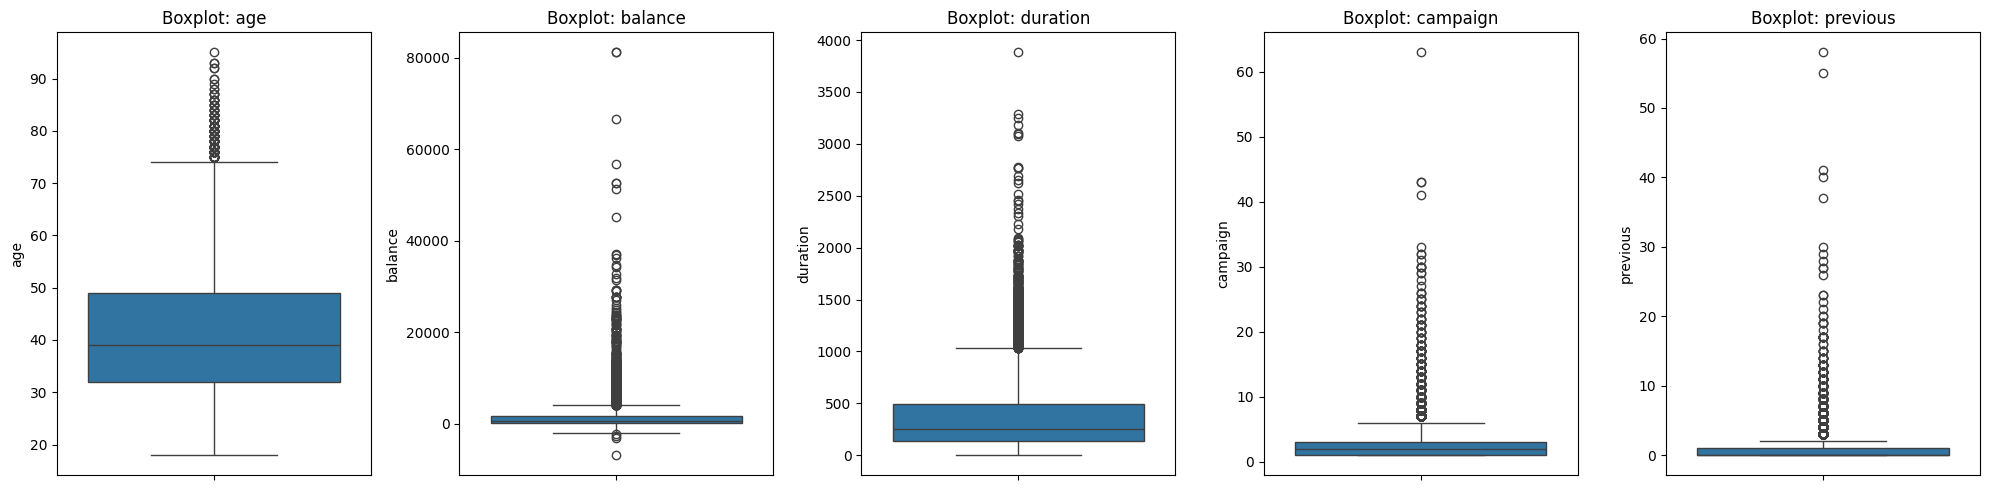

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f'Boxplot: {col}')
plt.tight_layout()
plt.show()

In [ ]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower) | (data[column] > upper)]
    return outliers, lower, upper

for col in num_cols:
    out, low, up = detect_outliers_iqr(df, col)
    print(f"{col}: выбросов {len(out)}, границы [{low:.1f}, {up:.1f}]")

age: выбросов 171, границы [6.5, 74.5]
balance: выбросов 1055, границы [-2257.0, 4087.0]
duration: выбросов 636, границы [-399.0, 1033.0]
campaign: выбросов 601, границы [-2.0, 6.0]
previous: выбросов 1258, границы [-1.5, 2.5]


In [ ]:
for col in num_cols:
    z = np.abs(stats.zscore(df[col]))
    print(f"{col} (Z-score > 3): {(z > 3).sum()} выбросов")

age (Z-score > 3): 132 выбросов
balance (Z-score > 3): 173 выбросов
duration (Z-score > 3): 201 выбросов
campaign (Z-score > 3): 210 выбросов
previous (Z-score > 3): 220 выбросов


In [ ]:
for col in num_cols:
    lower_bound = df[col].quantile(0.05)
    upper_bound = df[col].quantile(0.95)
    df[col + '_winsorized'] = df[col].clip(lower=lower_bound, upper=upper_bound)
    print(f"{col} До: min={df[col].min():.2f}, max={df[col].max():.2f} | "
          f"После: min={df[col + '_winsorized'].min():.2f}, max={df[col + '_winsorized'].max():.2f}")

age До: min=18.00, max=95.00 | После: min=26.00, max=61.00
balance До: min=-6847.00, max=81204.00 | После: min=-54.95, max=6026.45
duration До: min=2.00, max=3881.00 | После: min=51.00, max=1079.90
campaign До: min=1.00, max=63.00 | После: min=1.00, max=7.00
previous До: min=0.00, max=58.00 | После: min=0.00, max=5.00


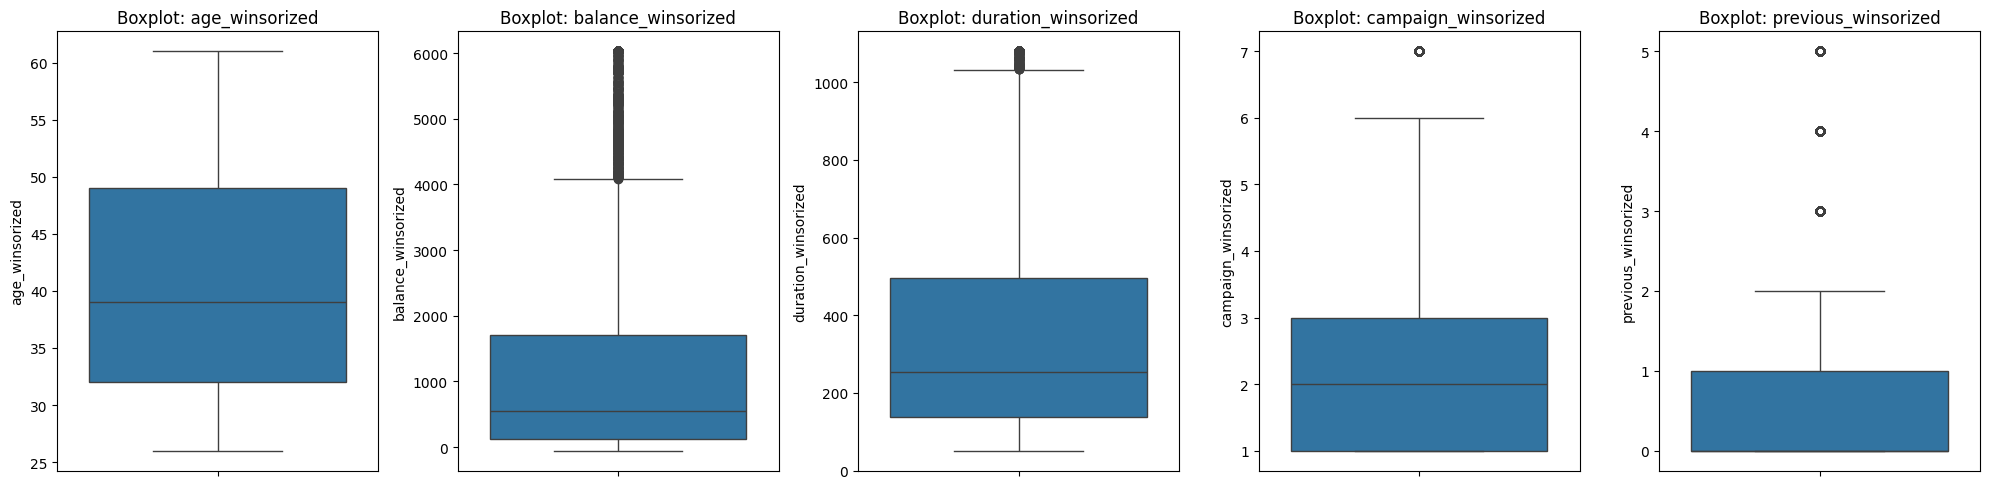

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col + '_winsorized'], ax=ax)
    ax.set_title(f'Boxplot: {col}_winsorized')
plt.tight_layout()
plt.show()

<Axes: ylabel='Frequency'>

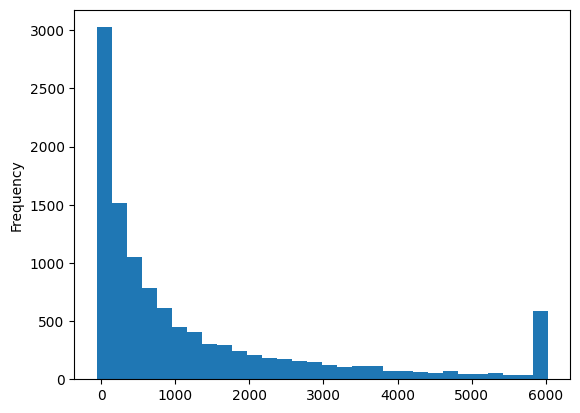

In [ ]:
#Построить гистограмму
df['balance_winsorized'].plot(kind='hist', bins = 30)

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

w_cols = [c + '_winsorized' for c in num_cols]

df_std = pd.DataFrame(StandardScaler().fit_transform(df[w_cols]),
                      columns=[c + '_std' for c in num_cols], index=df.index)
df_minmax = pd.DataFrame(MinMaxScaler().fit_transform(df[w_cols]),
                         columns=[c + '_minmax' for c in num_cols], index=df.index)
df = pd.concat([df, df_std, df_minmax], axis=1)

print(df_std.describe())
print(df_minmax.describe())

            age_std   balance_std  duration_std  campaign_std  previous_std
count  1.116200e+04  1.116200e+04  1.116200e+04  1.116200e+04  1.116200e+04
mean  -2.011571e-16 -5.092584e-18  8.148134e-17  6.111100e-17 -1.018517e-17
std    1.000045e+00  1.000045e+00  1.000045e+00  1.000045e+00  1.000045e+00
min   -1.408448e+00 -7.935392e-01 -1.055303e+00 -7.765805e-01 -4.867486e-01
25%   -8.390046e-01 -6.874022e-01 -7.548570e-01 -7.765805e-01 -4.867486e-01
50%   -1.746541e-01 -4.306820e-01 -3.508090e-01 -1.757077e-01 -4.867486e-01
75%    7.744180e-01  2.639020e-01  4.814608e-01  4.251652e-01  2.426229e-01
max    1.913305e+00  2.854167e+00  2.497902e+00  2.828657e+00  3.160109e+00
         age_minmax  balance_minmax  duration_minmax  campaign_minmax  \
count  11162.000000    11162.000000     11162.000000     11162.000000   
mean       0.424007        0.217545         0.297000         0.215403   
std        0.301059        0.274157         0.281449         0.277387   
min        0.000000     

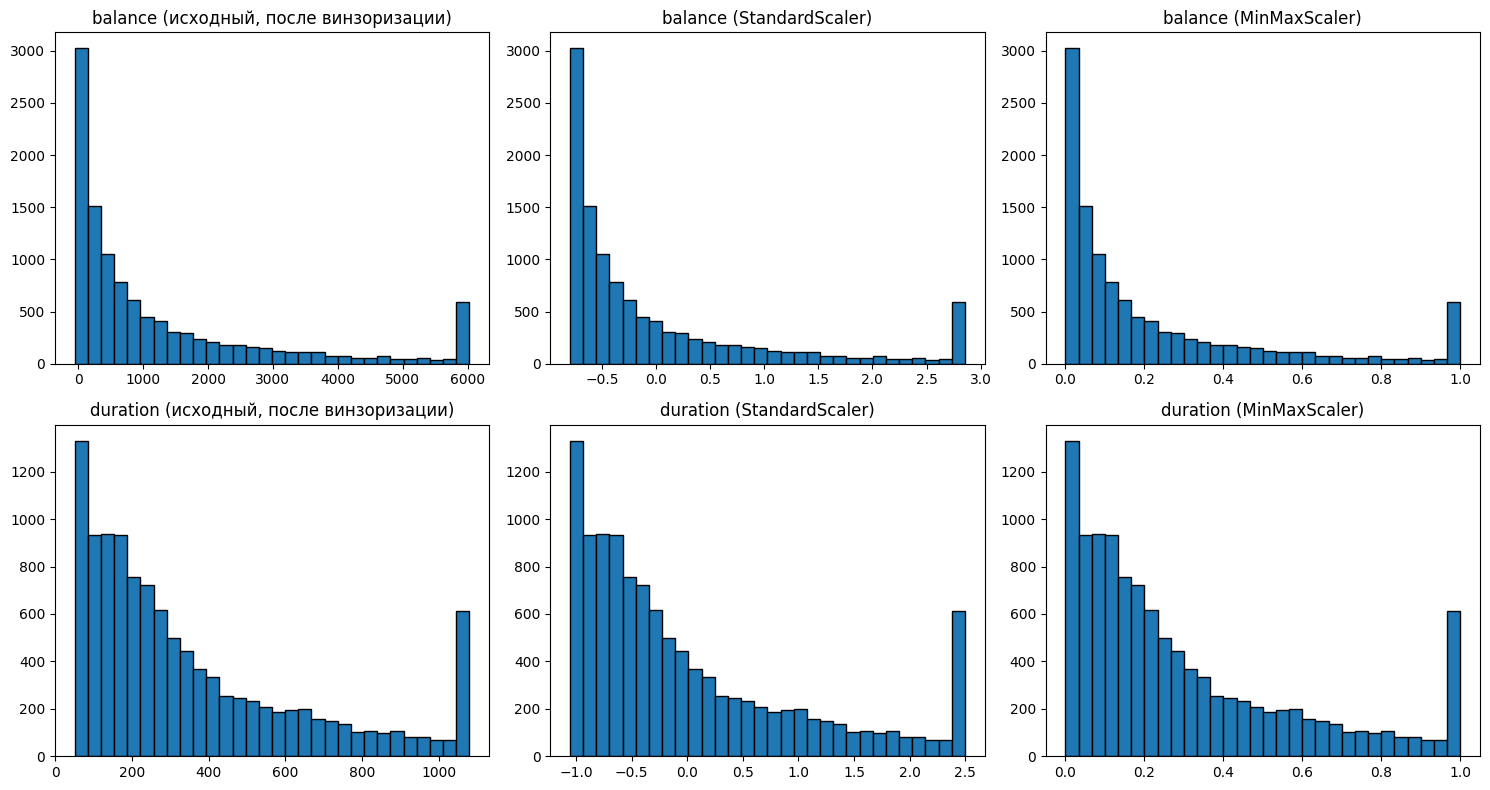

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(['balance', 'duration']):
    axes[i, 0].hist(df[col + '_winsorized'], bins=30, edgecolor='black')
    axes[i, 0].set_title(f'{col} (исходный, после винзоризации)')
    axes[i, 1].hist(df[col + '_std'], bins=30, edgecolor='black')
    axes[i, 1].set_title(f'{col} (StandardScaler)')
    axes[i, 2].hist(df[col + '_minmax'], bins=30, edgecolor='black')
    axes[i, 2].set_title(f'{col} (MinMaxScaler)')
plt.tight_layout()
plt.show()

In [ ]:
df_clean = df.copy()
for col in num_cols:
    df_clean[col] = df_clean[col + '_winsorized']

helper_cols = [c for c in df_clean.columns if c.endswith(('_winsorized', '_std', '_minmax'))]
df_clean = df_clean.drop(columns=helper_cols)

print(df_clean.shape)
print('Пропусков:', df_clean.isnull().sum().sum())
print(df_clean[num_cols].describe())

df_clean.to_csv('bank_clean.csv', index=False)

(11162, 17)
Пропусков: 0
                age       balance      duration      campaign      previous
count  11162.000000  11162.000000  11162.000000  11162.000000  11162.000000
mean      40.840262   1268.026563    356.583596      2.292421      0.667354
std       10.537079   1667.259598    289.582528      1.664320      1.371105
min       26.000000    -54.950000     51.000000      1.000000      0.000000
25%       32.000000    122.000000    138.000000      1.000000      0.000000
50%       39.000000    550.000000    255.000000      2.000000      0.000000
75%       49.000000   1708.000000    496.000000      3.000000      1.000000
max       61.000000   6026.450000   1079.900000      7.000000      5.000000
